# TD8: Power of a statistical test

Christelle Gonindard & Matthias Grenié


## 1. Background

A statistical test is a procedure for deciding between two hypotheses. It involves
inferential statistics: based on calculations performed on observed data, we draw conclusions about the
conclusions about the population, attaching to them risks of being wrong.
The following table highlights the two possible risks of error:

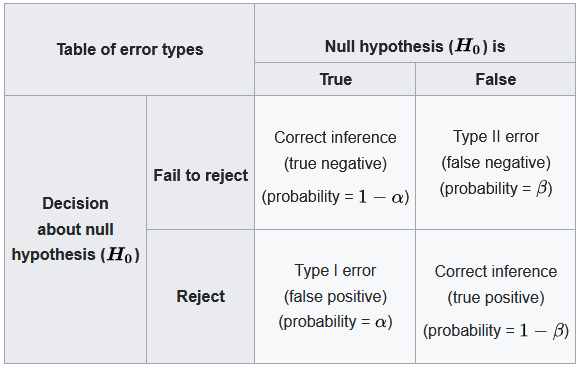

In this section, we propose to test the influence of sample size and initial
initial conditions on the $\alpha$ and $\beta$ risks of error in Student's t-test of two independent
independent samples.

## 2. Risk of error of Type I error

This represents the probability of adopting the alternative hypothesis H1 when in fact the null hypothesis
H0 is true:

$$\alpha = P(\textrm{reject }H_0 | H_0 \textrm{ true})$$ 

During a test, the experimenter is entirely free to set the upper limit of this risk of error
risk of error, known as the significance level or threshold, and generally noted as $\alpha$.

However, the usual thresholds are 0.05 or 5% and 0.01 or 1%. We
set it here at 0.05.

We are going to simulate two populations with a mean cholesterol level of 1.6 mg/L with
a standard deviation of 0.4 mg/L, following two different distributions:
- population A follows a normal distribution
- population B follows an exponential distribution


We will also simulate two other populations with a mean cholesterol level of
2 mg/L with a standard deviation of 0.4 mg/L, following two different distributions:
- population C follows a normal distribution
- population D follows an exponential distribution

From these two populations, we will first extract two independent samples
A1 and A2 from population A, which we will compare using a Student's t-test
then two independent samples B1 and B2 from population B, which we will also compare
with a Student's t-test. Since the samples belong to the same population, the
student test should have a pvalue greater than 0.05, corresponding to hypothesis H0.
We will repeat this experiment 10 times.


In [1]:
# Part containing the programming of the sample comparison function using an independent Student's t-test
# Simply run this cell

check.test = function(test, samplesize, sampledist1, sampledist2, count) 
{
  resultat <- rep(0,count)
  for (i in 1:count) 
    resultat[i] <- test(sampledist1(samplesize), sampledist2(samplesize))
  resultat
}

t.test.pvalue = function(x, y) t.test(x, y)$p.value

norm_equal = function(x) rnorm(x, 1.6, 0.4)
norm_different = function(x) rnorm(x, 2, 0.4)


exp_equal = function(x) rexp(x, 1/1.6)
exp_different = function(x) rexp(x, 1/2)


plot_pvalues = function(sample_size, sample_type, number_of_samples, sample_distribution)
{
  if(sample_type=="equal" & sample_distribution=="normal")
    plot(
        factor(
            check.test(t.test.pvalue, sample_size, norm_equal, norm_equal, number_of_samples) > 0.05
        ),
        main = "Equal samples, Normal distribution"
    )
  if(sample_type=="different" & sample_distribution=="normal")
    plot(
        factor(
            check.test(t.test.pvalue, sample_size, norm_equal, norm_different, number_of_samples) > 0.05
        ),
        main = "Different samples, Normal distribution"
    )
  if(sample_type=="equal" & sample_distribution=="exponential")
    plot(
        factor(
            check.test(t.test.pvalue, sample_size, exp_equal, exp_equal, number_of_samples) > 0.05
        ),
        main = "Equal samples, Exponential distribution"
    )
  if(sample_type=="different" & sample_distribution=="exponential")
    plot(
        factor(
            check.test(t.test.pvalue, sample_size, exp_equal, exp_different, number_of_samples) > 0.05),
        main = "Different samples, Exponential distribution"
    )
}




The `plot_pvalues()` function, which performs a series of Student's t-tests on several independent samples and
returns a graph representing the decisions made by the test. This function accepts three
arguments:

```
plot_pvalues(sample_size, sample_type, number_of_samples, sample_distribution)
```

- **`sample_size`** : the size of the samples to be extracted
- **`sample_type`**: the term "equal" corresponds to two samples
extracted from the same population and "different" corresponds to two samples
extracted from two different populations but with the same law
- **`number_of_samples`**: number of samples extracted, which corresponds to the number of
of Student's t tests to be performed
- **`sample_distribution`**: the theoretical distribution of the chosen population, which can be either `"normal"` or `"exponential"`.

The FALSE column on the graph indicates the number of times H0 is rejected, and the
TRUE column indicates the number of times H0 cannot be rejected.

**First example**: Let's simulate 1000 pairs of two samples belonging to the same population.
population, of large sizes (n=100) and following a normal or exponential distribution

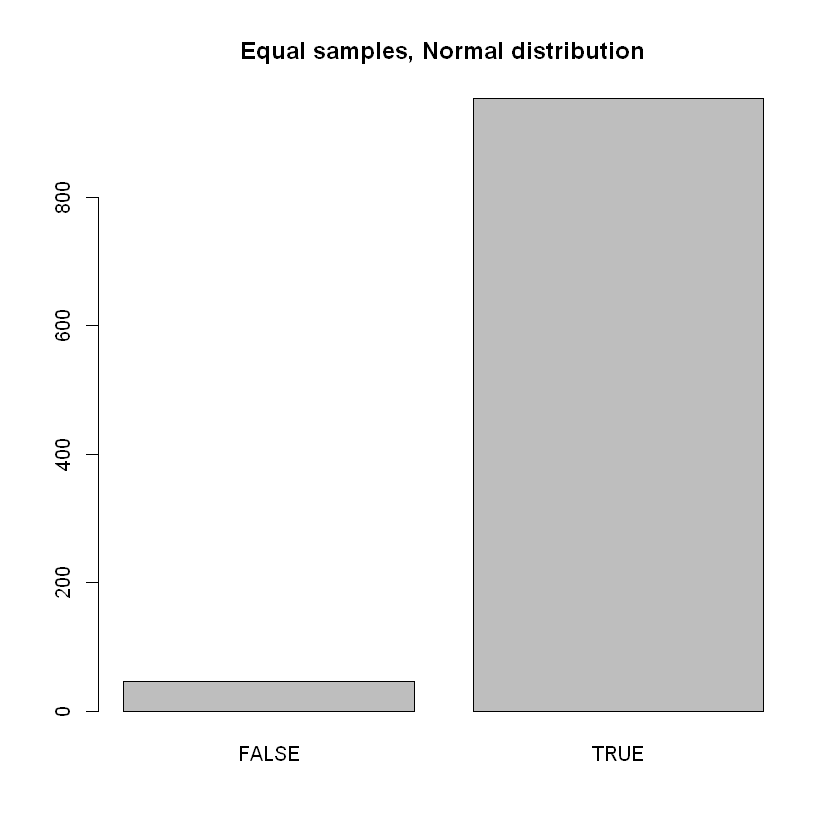

In [2]:
# Simulation of 1000 pairs of independent samples of size 100 following 
# a normal distribution from the same population
plot_pvalues(100, "equal", 1000, "normal")

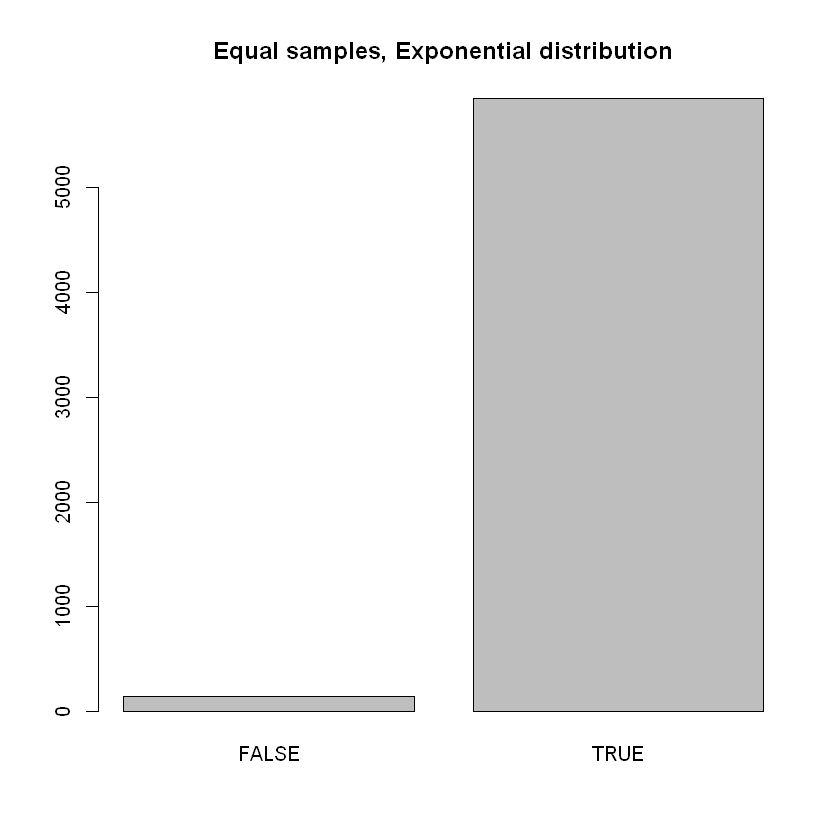

In [3]:
# Simulation of 1000 pairs of independent samples of size 100 
# following an exponential distribution and coming from the same population
plot_pvalues(100, "equal", 6000, "exponential")

We note that in both cases, whether for samples following a normal distribution
or for samples following an exponential distribution, the H0 hypothesis is very rarely
rejected (False column).


**Second example**: Let's simulate 1000 pairs of two independent samples belonging to the same
population, of small size (n=5), following a normal distribution or an exponential distribution

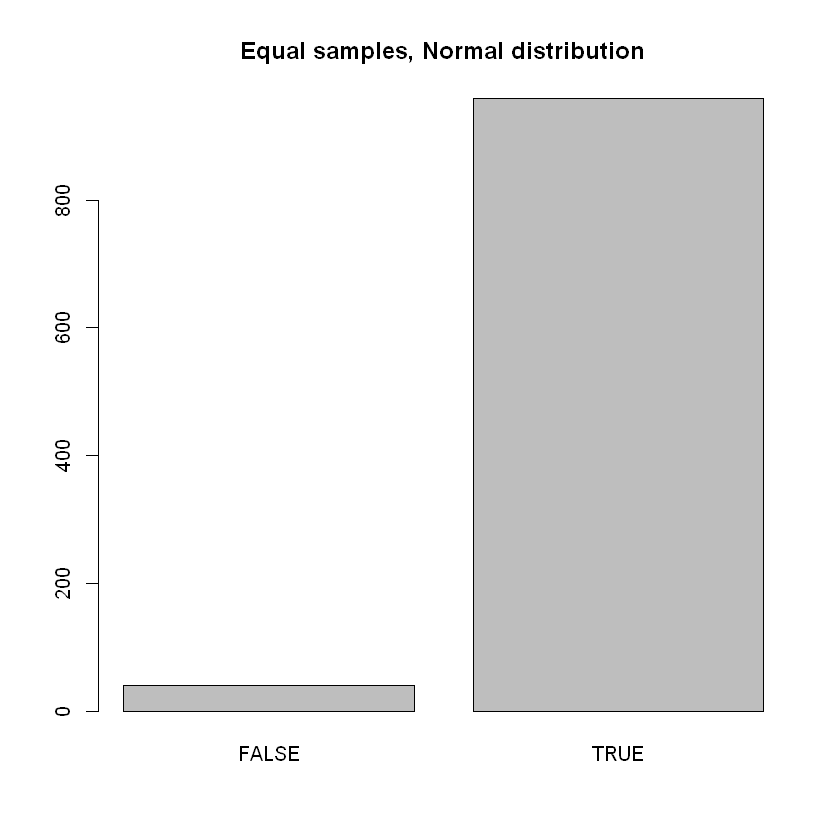

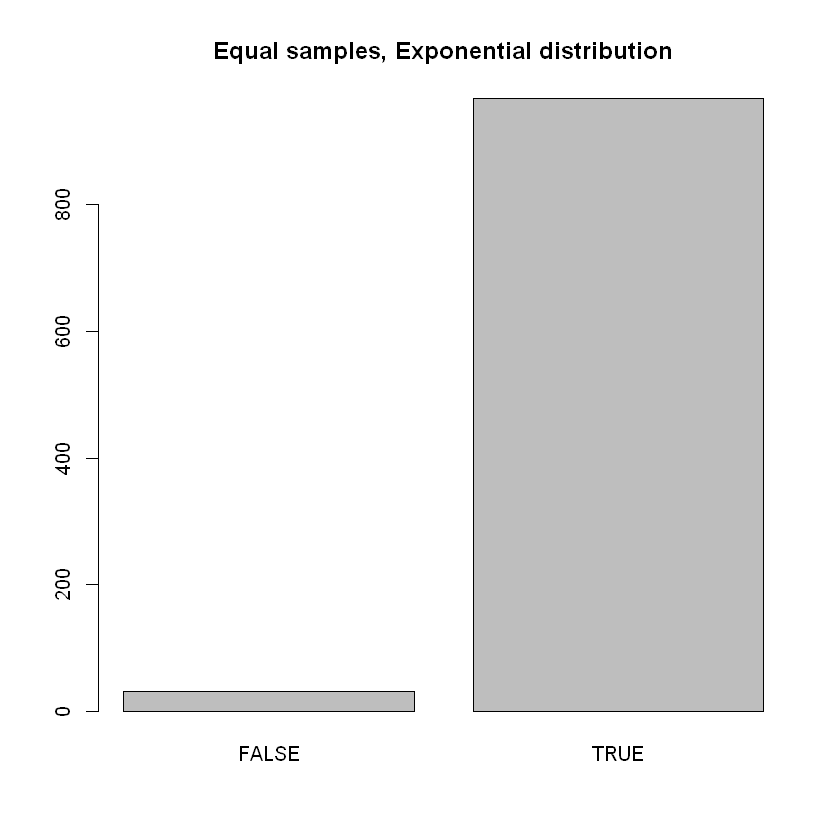

In [4]:
# Simulation of 1000 pairs of independent samples of size 5 following 
# a normal distribution and from the same population
plot_pvalues(5, "equal", 1000, "normal")

# Simulation of 1000 pairs of independent samples of size 5 following 
# an exponential distribution from the same population
plot_pvalues(5, "equal", 1000, "exponential")

In both cases, whether for samples following a normal distribution or a uniform distribution
for samples following a uniform distribution, the H0 hypothesis is very rarely rejected (column
False).

You can practice testing other simulations. 

## 3. Type II error

It represents the probability of accepting H0 when in fact H1 is true:

$$ \beta = P(\textrm{acceptance of } H_0 | H_0 \textrm{ is false})$$

\beta$ characterizes the test's lack of power, i.e. its inability to highlight
between the parameters being compared.

1 - $\beta$ characterizes the power of the test. It depends on the form of the alternative hypothesis
and, for a given $\alpha$ value, is all the better the **sample size used.**
In standard tests, with sample sizes set by the experimenter, the greater the
the smaller the sample size chosen by the experimenter, the higher the value of $\beta$, and vice versa.
are linked. In general, these risks are chosen to be of the same order of magnitude.

The power of a test depends on the nature of H1: a one-tailed test is more powerful than a two-tailed test.
two-tailed test. It increases with the size of the sample N studied at a constant $\alpha$ value and
decreases as $\alpha$ decreases.

Let's test the power of Student's t-test:

**Third example**: Simulate 1000 pairs of two independent samples from two different large populations
different large populations (n=100), following a normal distribution (let's test population A
against population C) or an exponential distribution (let's test population B against population D).

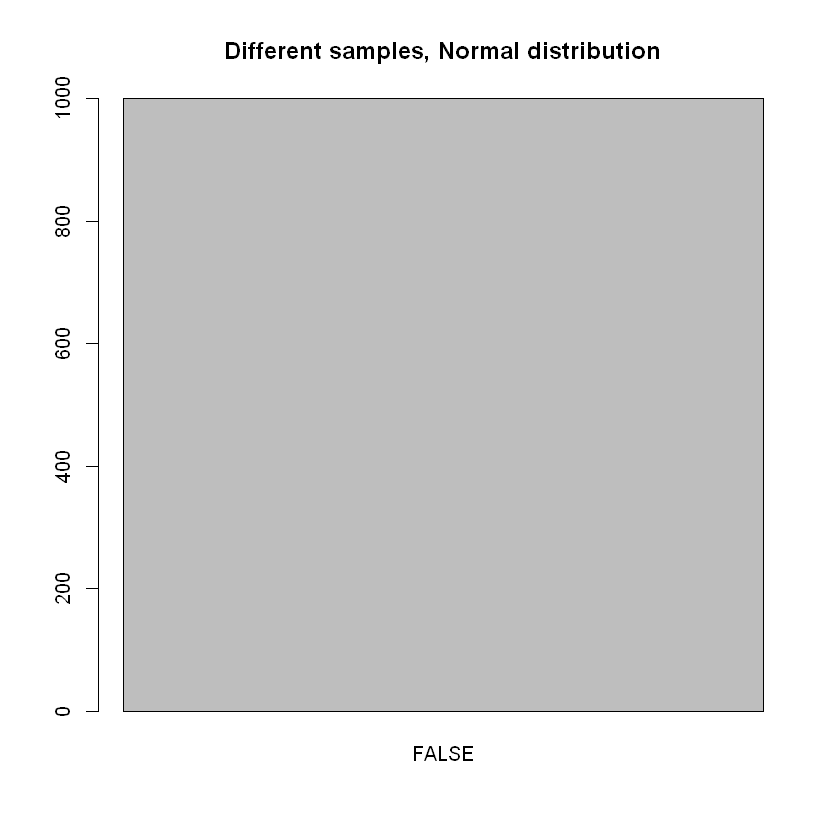

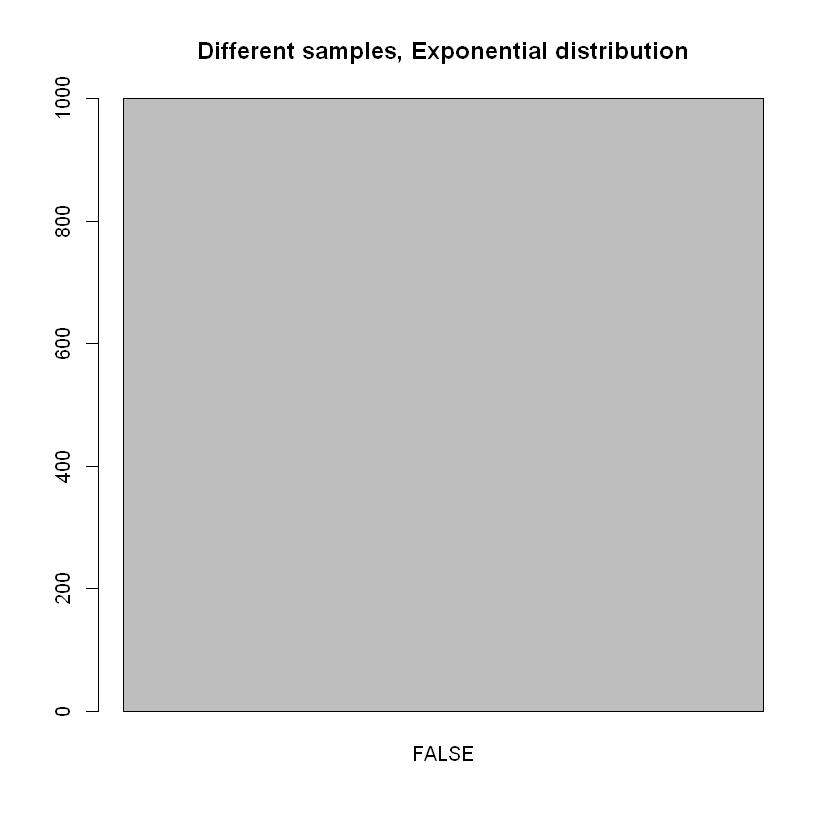

In [5]:
# Simulation of 1000 pairs of samples of size 100 
# following a normal distribution
plot_pvalues(100, "different", 1000, "normal")

# Simulation of 1000 pairs of samples of size 100 
# following an exponential distribution
plot_pvalues(100, "different", 1000, "exponential")

When comparing two different populations of large samples (n=100) following a normal
the Student test systematically rejects the H0 hypothesis. On the other hand
samples follow an exponential distribution, the Student's t test is often wrong.
(H0 is not rejected in the majority of cases, which corresponds to a false test response).


**Fourth example**: Let's simulate 1000 pairs of two independent samples from two different
different populations of small size (n=5) and following a normal distribution (let's test population A
against population C) or an exponential distribution (let's test population B against population D).


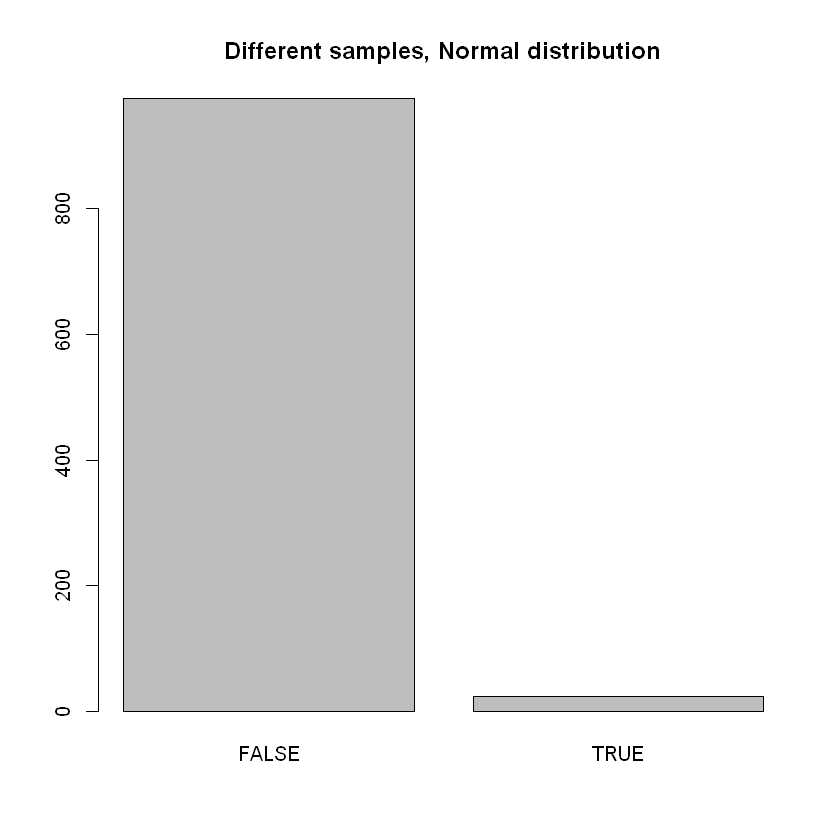

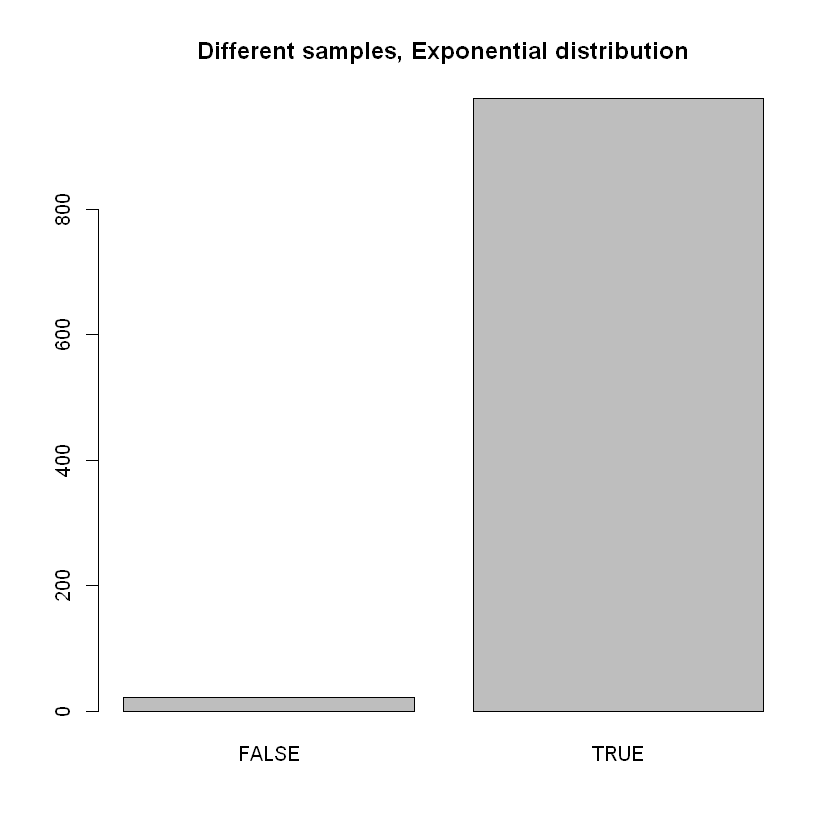

In [6]:
# Simulation of 1000 pairs of independent samples of size 5
# following a normal distribution
plot_pvalues(5, "different", 1000, "normal")

# Simulation of 1000 pairs of independent samples of size 5
# following an exponential distribution
plot_pvalues( 5, "different", 1000, "exponential")

When comparing two different populations of small samples (n=5) following a normal
Student's t-test very often rejects H0, but is still wrong. In
If, on the other hand, the two samples follow an exponential distribution, the Student's test
is wrong in the vast majority of cases (H0 is not rejected in the majority of cases, which
corresponds to a false test response).


**To conclude:  
The power of the Student's t-test depends strongly on the sample size.  
The greater the sample size, the greater the power of the test.  
When the sample size is small the normality of the data improves the test's power.**